# Dimensionamento de Pára-raios

Existem três métodos de proteção contra descargas atmosféricas definidos pela NBR 5419-3:2015: 

1.   método do ângulo de proteção ou método de Franklin;
2.   método das malhas; e
3.   método da esfera rolante.


## Método da esfera rolante ou eletrogeométrico

Também conhecido como método eletrogeométrico, se baseia na delimitação do volume de proteção dos captores de um Sistema de Proteção contra Descargas Atmosféricas, podendo ser utilizados hastes, cabos ou mesmo uma combinação de ambos. É empregado com muita eficiência em estruturas de formas arquitetônicas complexas. Em função dessa característica, o método da esfera rolante tem bastante aplicação em subestação de potência de instalação exterior.

Fundamenta na premissa de uma esfera de raio $R_e$, com o centro localizado na extremidade do líder antes
de seu último salto, conforme visto na Figura. Os pontos da superfície desta esfera são o lugar geométrico que deve ser atingido por uma descarga atmosférica.

A zona protegida é definida como a região em que a esfera rolante não consegue tocar, exceto nos captores.

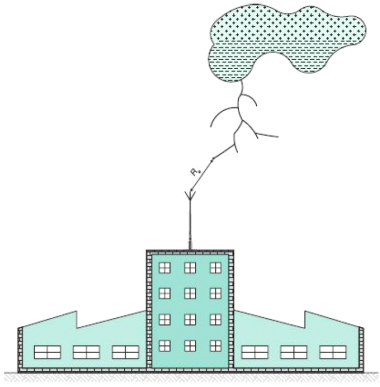

A aplicação do método da esfera rolante envolve dois diferentes casos:
* Volume de proteção de um captor vertical quando a altura do captor $H_c$ é inferior a $R_e$
* Volume de proteção de um captor vertical quando a altura $H_c$ é superior a $R_e$

### Volume de proteção de um captor vertical quando a altura do captor $H_c$ é superior a $R_e$

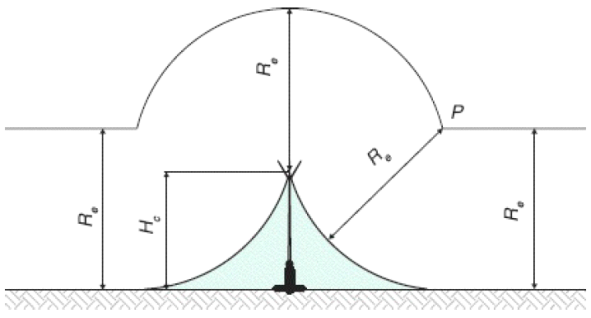

Considerando a origem do nosso sistema de referências carteziano o captor, o raio de proteção fica definido pelo conjunto de pontos fora do alcance do volume da esfera, em termos matemáticos definido por $(1)$:

\begin{equation}
{\left( {x - {R_e}} \right)^2} + {\left( {y - {0}} \right)^2} \ge R_e^2
\tag{1}
\end{equation}

> o ponto $P$ à direita tem coordenadas $(R_e,0)$

O valor de $R_e$ representa a distância entre o ponto de partida do líder ascendente e a extremidade do líder descendente, é o parâmetro utilizado para o projeto do posicionamento dos captores no modelo eletrogeométrico, sendo que se pode calcular essa distância através do valor de crista máximo do primeiro raio negativo, em ${\rm kA}$

\begin{equation}
d = k\,{I^p}
\tag{2}
\end{equation}

Esta equação foi elaborada pelo ${\rm GT 33}$ da ${\rm CIGRE}$  (Conseil International des Grands Réseaux Electriques | Conferência Internacional de Grandes Redes Elétricas de Alta Tensão). 

A ${\rm ABNT \; NBR \, 5419}$ utiliza $k=10$ e $p=0,65$, assim:

\begin{equation}
{R_e} = 10I_{\max }^{0,65}
\tag{3}
\end{equation}

A Equação $(3)$ demonstra que a distância de atração é função da intensidade de $I_{\max}$, de forma que durante a
aproximação do líder descendente, a parte da estrutura que se encontrar a uma distância menor que o raio ${R_e}$ tem maior probabilidade de sofrer o impacto deste.

> Os valores de ${R_e}$ são limitados a $20 \, {\rm m}$ para estruturas com nível de proteção $I$, que é o caso de subestações externas. Verificaremos que esse sempre será o caso.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# E0 = 1.5e6 # V/m ==> is the limiting corona gradient, this is taken equal to 1500 kV/m
# comprimento_mínimo_do_isolador = 350e-3
BIL_do_isolador = 170e3
# Corrente de crista
I_crista = 3 #kA

# Raio da esfera (metros)
Re = 10*I_crista**(2/3)
Re = np.floor(Re)



# Altura do captor (metros)
Hc = 12

# Domínio de cálculo à direita do captor
x = np.linspace(-Re, Re, 101)
y = np.linspace( 0,  Hc, 101)
xx, yy = np.meshgrid(x, y)

# Probabilidade do raio acontecer como esperado
P = 1 / (1 + (I_crista/24)**(2.6) )
100*P

99.5532941203493

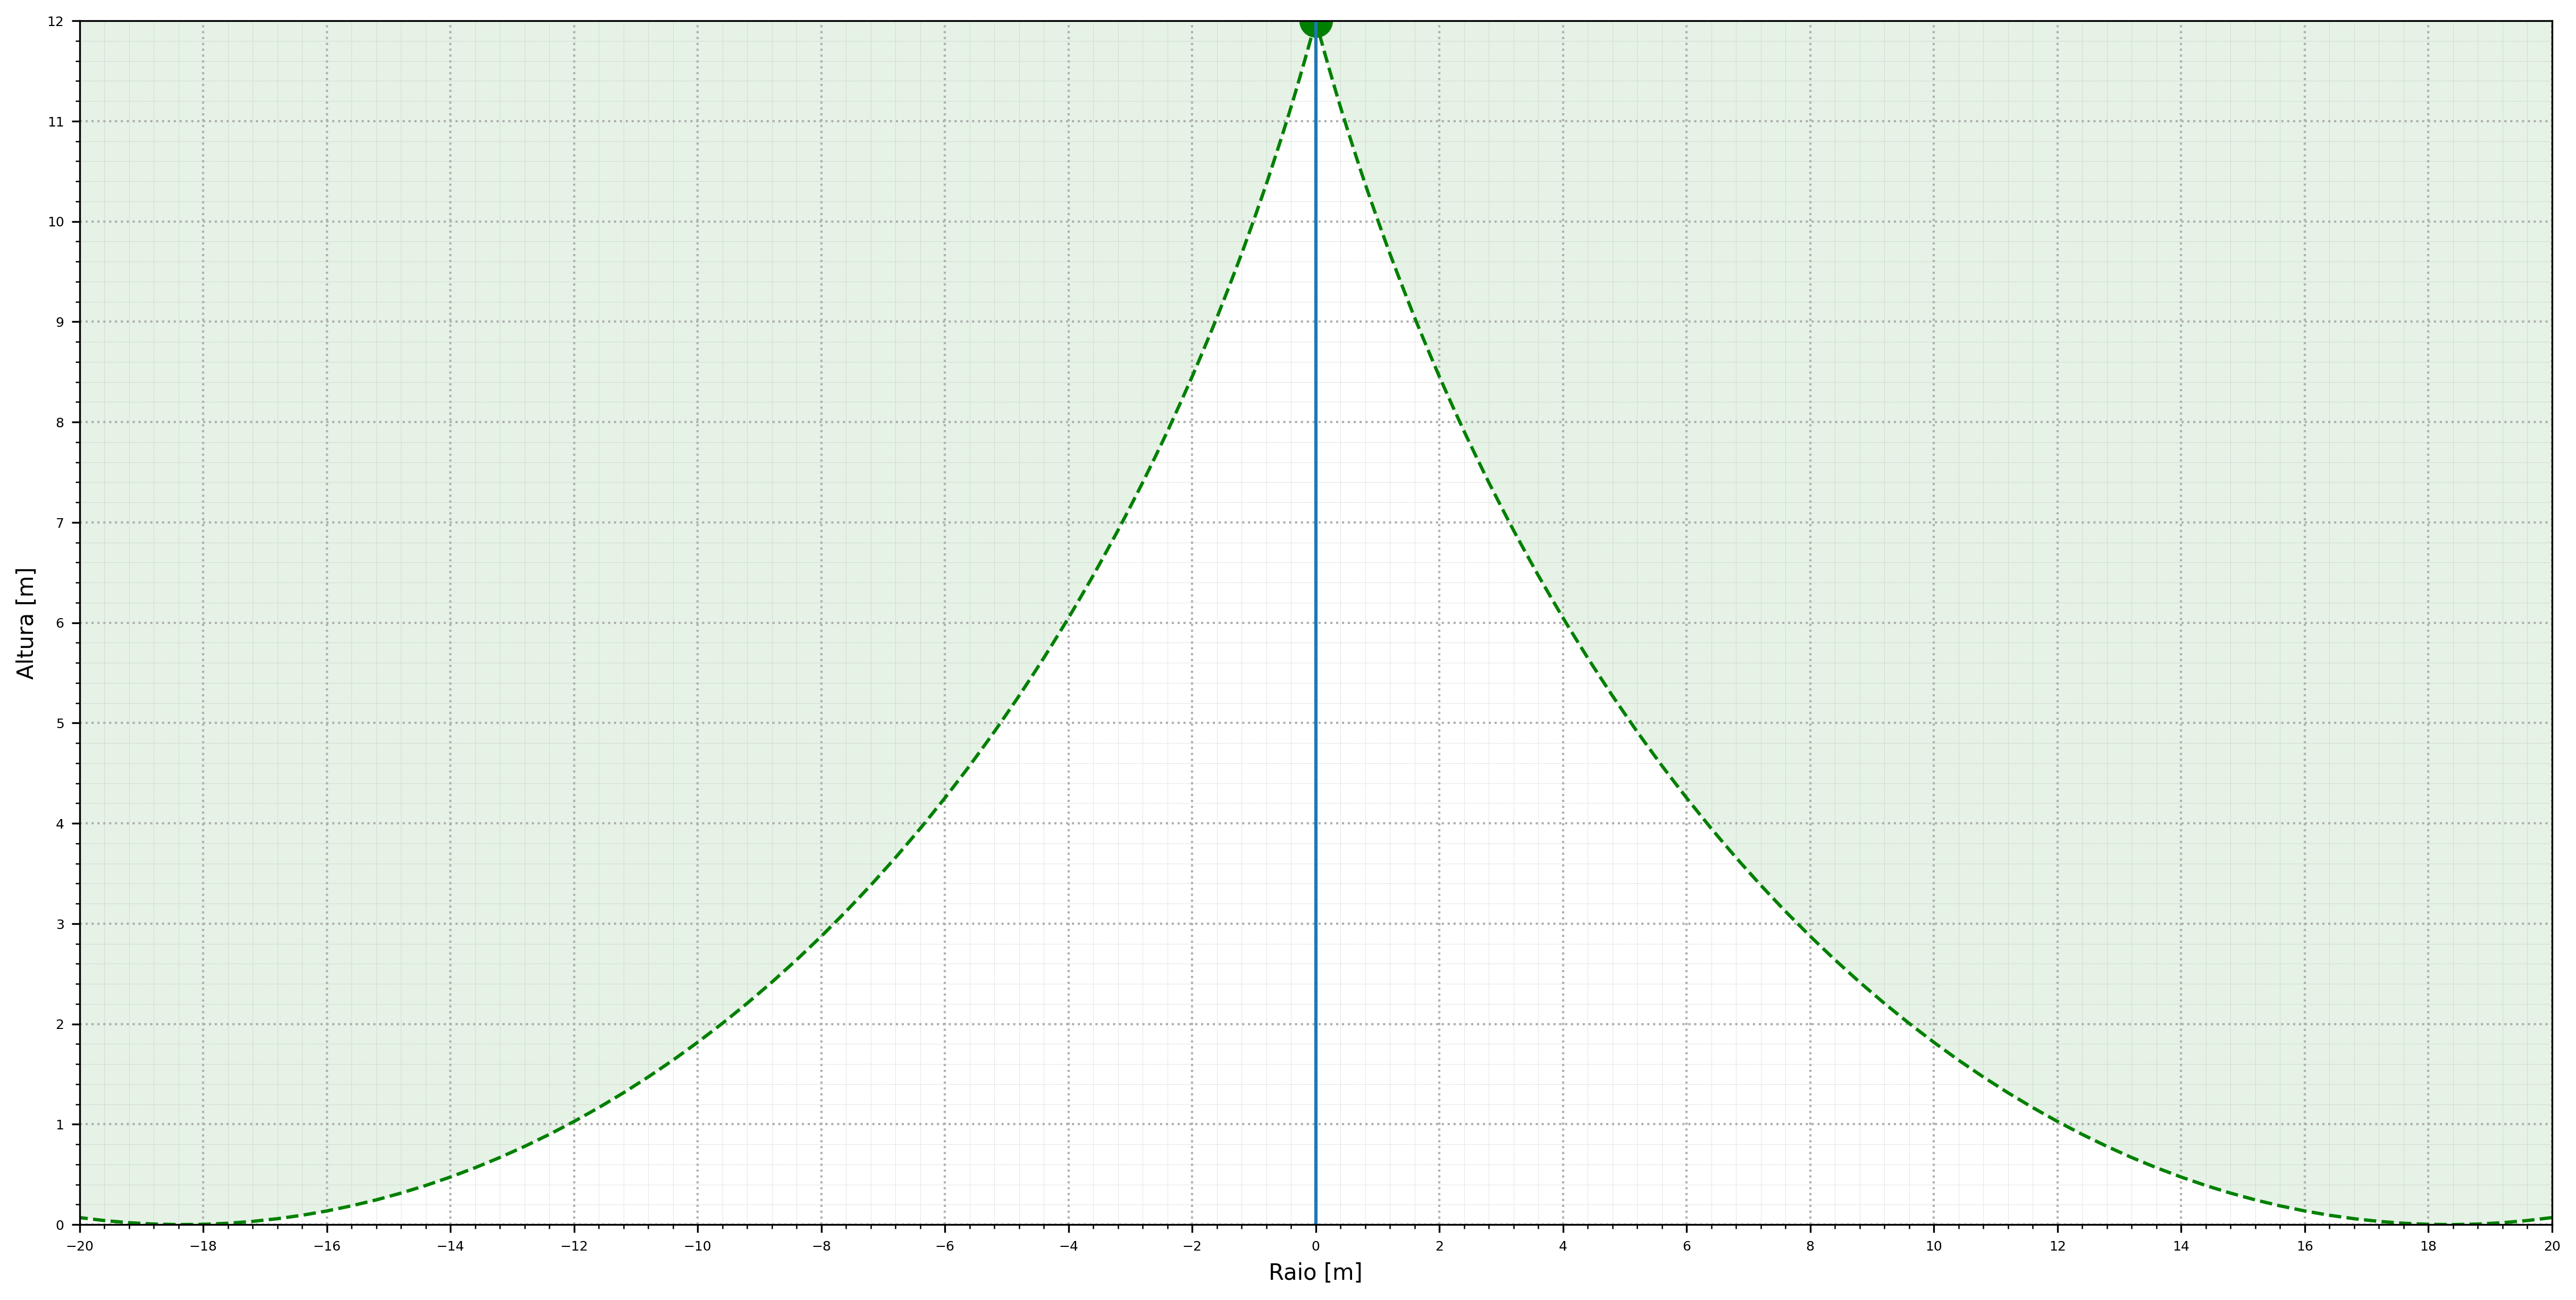

In [ ]:
fig, ax = plt.subplots(dpi=300, figsize=(20,10))

# esfera do captor
# x0 = 0
# y0 = Hc
# zz0 = (xx-x0)**2 + (yy-y0)**2
# ax.contourf(xx, yy ,zz0, [0, Re**2], linestyles='dashed', colors='blue', alpha=0.1)
# plt.scatter(x0, y0, color='blue')

# esfera à direita
x0 = np.sqrt(Re**2 - (Re-Hc)**2)
y0 = Re
zz1 = (xx-x0)**2 + (yy-y0)**2
ax.contourf(xx, yy ,zz1, [0, Re**2], colors='green', alpha=0.1)
ax.contour(xx, yy ,zz1, [0, Re**2], linestyles='dashed', colors='green')
# plt.scatter(x0, y0, color='green')

# esfera à esquerda
x0 = -np.sqrt(Re**2 - (Re-Hc)**2)
y0 = Re
zz2 = (xx-x0)**2 + (yy-y0)**2
ax.contourf(xx, yy ,zz2, [0, Re**2], colors='green', alpha=0.1)
ax.contour(xx, yy ,zz2, [0, Re**2], linestyles='dashed', colors='green')
# plt.scatter(x0, y0, color='red')

# captor
y_captor = np.array([0 , Hc])
x_captor = np.array([0 , 0])
plt.plot(x_captor, y_captor)
plt.scatter(0, Hc, s=200, color='green')


# # chave seccionadora
# l_sec = 2 # comprimento
# h_sec = 3 # altura
# x0_sec = -8 # posição
# y_sec = np.array([0 , h_sec, h_sec, 0])
# x_sec = np.array([x0_sec , x0_sec, x0_sec+l_sec, x0_sec+l_sec])
# plt.plot(x_sec, y_sec, color='red')
# plt.scatter(x_sec, y_sec, s=50, color='red')

ax.set_xlabel("Raio [m]")
ax.set_ylabel("Altura [m]")
xlim = Re
ax.set_xticks(np.arange(-xlim, 0.01+xlim, 2))
ax.set_yticks(np.arange(-0,    0.01+Hc,   1))
ax.tick_params(axis='both', which='major', labelsize=6)
ax.grid(ls=":", lw=1)
from matplotlib.ticker import AutoMinorLocator
minor_locator = AutoMinorLocator(5)
ax.xaxis.set_minor_locator(minor_locator)
minor_locator = AutoMinorLocator(5)
ax.yaxis.set_minor_locator(minor_locator)
plt.grid(which='minor',ls=":", lw=0.2)
fig.show()

# Daqui para baixo é mais viagem... ✈::

# Um pouco a mais de teoria

Algumas relações adicionais precisam ser introduzidas antes de mostrar como o EGM é usado para projetar uma zona de proteção para equipamentos da subestação.

Os isoladores de barramento são geralmente selecionados para suportar um nível básico de impulso elétrico (BIL).

Os isoladores também podem ser escolhidos de acordo com outras características elétricas, incluindo tensão de flashover crítico de impulso de polaridade negativa (C.F.O.).

O flashover ocorre se a tensão produzida pela corrente do relâmpago fluindo através da impedância de surto do barramento da estação exceder o valor suportável.

\begin{equation}
{I_S} = \frac{{BIL \times 1.1}}{{\left( {\frac{{{Z_S}}}{2}} \right)}} = \frac{{2.2 \times BIL}}{{{Z_S}}}
\tag{5.2-A}
\end{equation}

ou 

\begin{equation}
{I_S} = \frac{{0.94 \times CFO}}{{\left( {\frac{{{Z_S}}}{2}} \right)}} = \frac{{2.068 \times CFO}}{{{Z_S}}}
\tag{5.2-B}
\end{equation}

onde:

* $I_S$ é a corrente de curso permitida em ${\rm kA}$
* $BIL$ (basic lightning impulse) é o nível básico de impulso do raio ${\rm kV}$
* $CFO$ (critical flashOver) é a tensão de flashover crítica de polaridade negativa do isolamento sendo considerado em ${\rm kV}$
* $Z_S$ é a impedância de surto do condutor através do qual o surto está passando em ohms
* $1.1$ é o fator a considerar para a redução da corrente de curso que termina em um condutor em comparação com a terra de impedância zero

## Cálculo do raio corona e impedância de surto sob corona

### Corona radius

No caso de um único condutor, o raio da coroa $R_c$ é dado por

\begin{equation}
{R_c}\ln \left( {\frac{{2h}}{{{R_c}}}} \right) - \frac{{{V_c}}}{{{E_0}}} = 0
\tag{C.1}
\end{equation}

onde:
* $R_c$ é o raio da coroa em metros
* $h$ é a altura média do condutor em metros
* $V_c$ é a tensão do isolador permitida para um surto de polaridade negativa com uma frente de 6 ms em quilovolts (Vc = o BIL para isoladores de poste)
* $E_0$ é o gradiente corona limitante, considerado igual a 1.500 kV/mm

No caso de condutores de feixe, o raio do feixe sob a coroa ${{R'}_c}$ é obtido da seguinte forma:

\begin{equation}
{{R'}_c} = {R_0} + {R_c}
\tag{C.2}
\end{equation}

onde:

* ${{R'}_c}$ é o valor para um único condutor dado pela Eq C.1
* ${R_0}$ é o raio equivalente do feixe.



### O método de cálculo de $R_0$ é dado em C.2

No caso de um feixe de condutores duplos, o raio equivalente $R_0$ é dado por

\begin{equation}
{R_0} = \sqrt {r \times l} 
\tag{C.3}
\end{equation}

onde:

* $r$ é o raio do subcondutor em metros
* $l$ é o espaçamento entre condutores adjacentes em metros

No caso de um feixe de três condutores:

\begin{equation}
{R_0} = \sqrt[3]{{r \times {l^2}}}
\tag{C.4}
\end{equation}

No caso de um feixe de quatro condutores:

\begin{equation}
{R_0} = \sqrt[4]{{\sqrt 2  \times r \times {l^3}}}
\tag{C.5}
\end{equation}

No caso de mais de quatro condutores:

\begin{equation}
{R_0} = 0.5 \times l' \times \sqrt[n]{{n \times \frac{{2 \times r}}{{l'}}}}
\tag{C.6}
\end{equation}

onde:

* $l'$ é o diâmetro do círculo no qual os subcondutores se encontram
* $n$ é o número de subcondutores


### Impedância de surto sob corona


A impedância de surto de condutores sob corona em ohms é dada por

\begin{equation}
{Z_S} = 60 \times \sqrt {\ln \left( {\frac{{2h}}{{{R_c}}}} \right)\ln \left( {\frac{{2h}}{r}} \right)} 
\tag{C.7}
\end{equation}

onde:

* $h$ é a altura média do condutor
* $R_c$ é o raio da coroa (use a Eq C.2 conforme apropriado)
* $r$ is the metallic radius of the conductor, or equivalent radius in the case of bundled conductors

Na Equação 5-2B, o CFO foi reduzido em 6% para produzir um nível suportável aproximadamente equivalente à classificação BIL para isoladores poste.

O uso do método da esfera rolante envolve rolar uma esfera imaginária de raio S sobre a superfície de uma subestação.

A esfera rola para cima (e é sustentada por) mastros de raios, fios blindados, cercas de subestações e outros objetos metálicos aterrados que podem fornecer proteção contra raios.

Diz-se que um equipamento está protegido de um golpe direto se permanecer abaixo da superfície curva da esfera em virtude da esfera ser elevada por fios blindados ou outros dispositivos.

Equipamentos que tocam a esfera ou penetram em sua superfície não são protegidos. O conceito básico é ilustrado na Figura 5-3.

Continuando a discussão sobre proteção contra corrente de curso I_s, considere primeiro um único mastro.

O modelo geométrico de um único mastro blindado de subestação, o plano de terra, a distância de ataque e a zona de proteção são mostrados na Figura 5-4.

Um arco de raio S que toca o mastro da blindagem e o plano de terra é mostrado na Þgura 5-4.

Todos os pontos abaixo deste arco são protegidos contra a corrente de descarga I_s. Esta é a zona protegida.

O arco é construído da seguinte forma (ver Þgura 5-4). Uma linha tracejada é traçada paralela ao solo a uma distância S (a distância de impacto obtida na Equação 5-1) acima do plano do solo.

Um arco de raio S, com seu centro localizado na linha tracejada, é desenhado de forma que o raio do arco apenas toque o mastro. Os líderes escalonados que resultam em I_s de corrente de golpe e que descem fora do ponto onde o arco é tangente ao solo atingirão o solo.


Os líderes escalonados que resultam em correntes de golpe I_s e que descem dentro do ponto onde o arco é tangente ao solo atingirão o mastro de blindagem, desde que todos os outros objetos estejam dentro da zona protegida.

A altura do mastro da blindagem que fornecerá a zona máxima de proteção para correntes de curso iguais a I_s é S. Se a altura do mastro for menor que S, a zona de proteção será reduzida.

Aumentar a altura do mastro da blindagem maior que S fornecerá proteção adicional no caso de um único mastro. Isso não é necessariamente verdade no caso de mastros múltiplos e fios blindados.

A zona de proteção pode ser visualizada como a superfície de uma esfera de raio S que rola em direção ao mastro até tocar o mastro.

À medida que a esfera é enrolada em torno do mastro, uma superfície tridimensional de proteção é definida.

É este conceito que levou ao nome esfera rolante para aplicações simplificadas do modelo eletrogeométrico.


### Proteção contra correntes de descarga maiores que $I_s$

A subseção 5.3.1 demonstrou a proteção fornecida para uma corrente de curso I_s.

No entanto, uma corrente de descarga atmosférica tem um número infinito de magnitudes possíveis, e o projetista da subestação deseja saber se o sistema fornece proteção em outros níveis de magnitude da corrente de descarga.

Consider a stroke current Is1 with magnitude greater than Is. 

Strike distance, determined from Eq 5-1, is S1. 

The geometrical model for this condition is shown in Figure 5-5. 

Arcs of protection for stroke current Is1 and for the previously discussed Is are both shown. 

The Figure shows that the zone of protection provided by the mast for stroke current Is1 is greater than the zone of protection provided by the mast for stroke current Is.



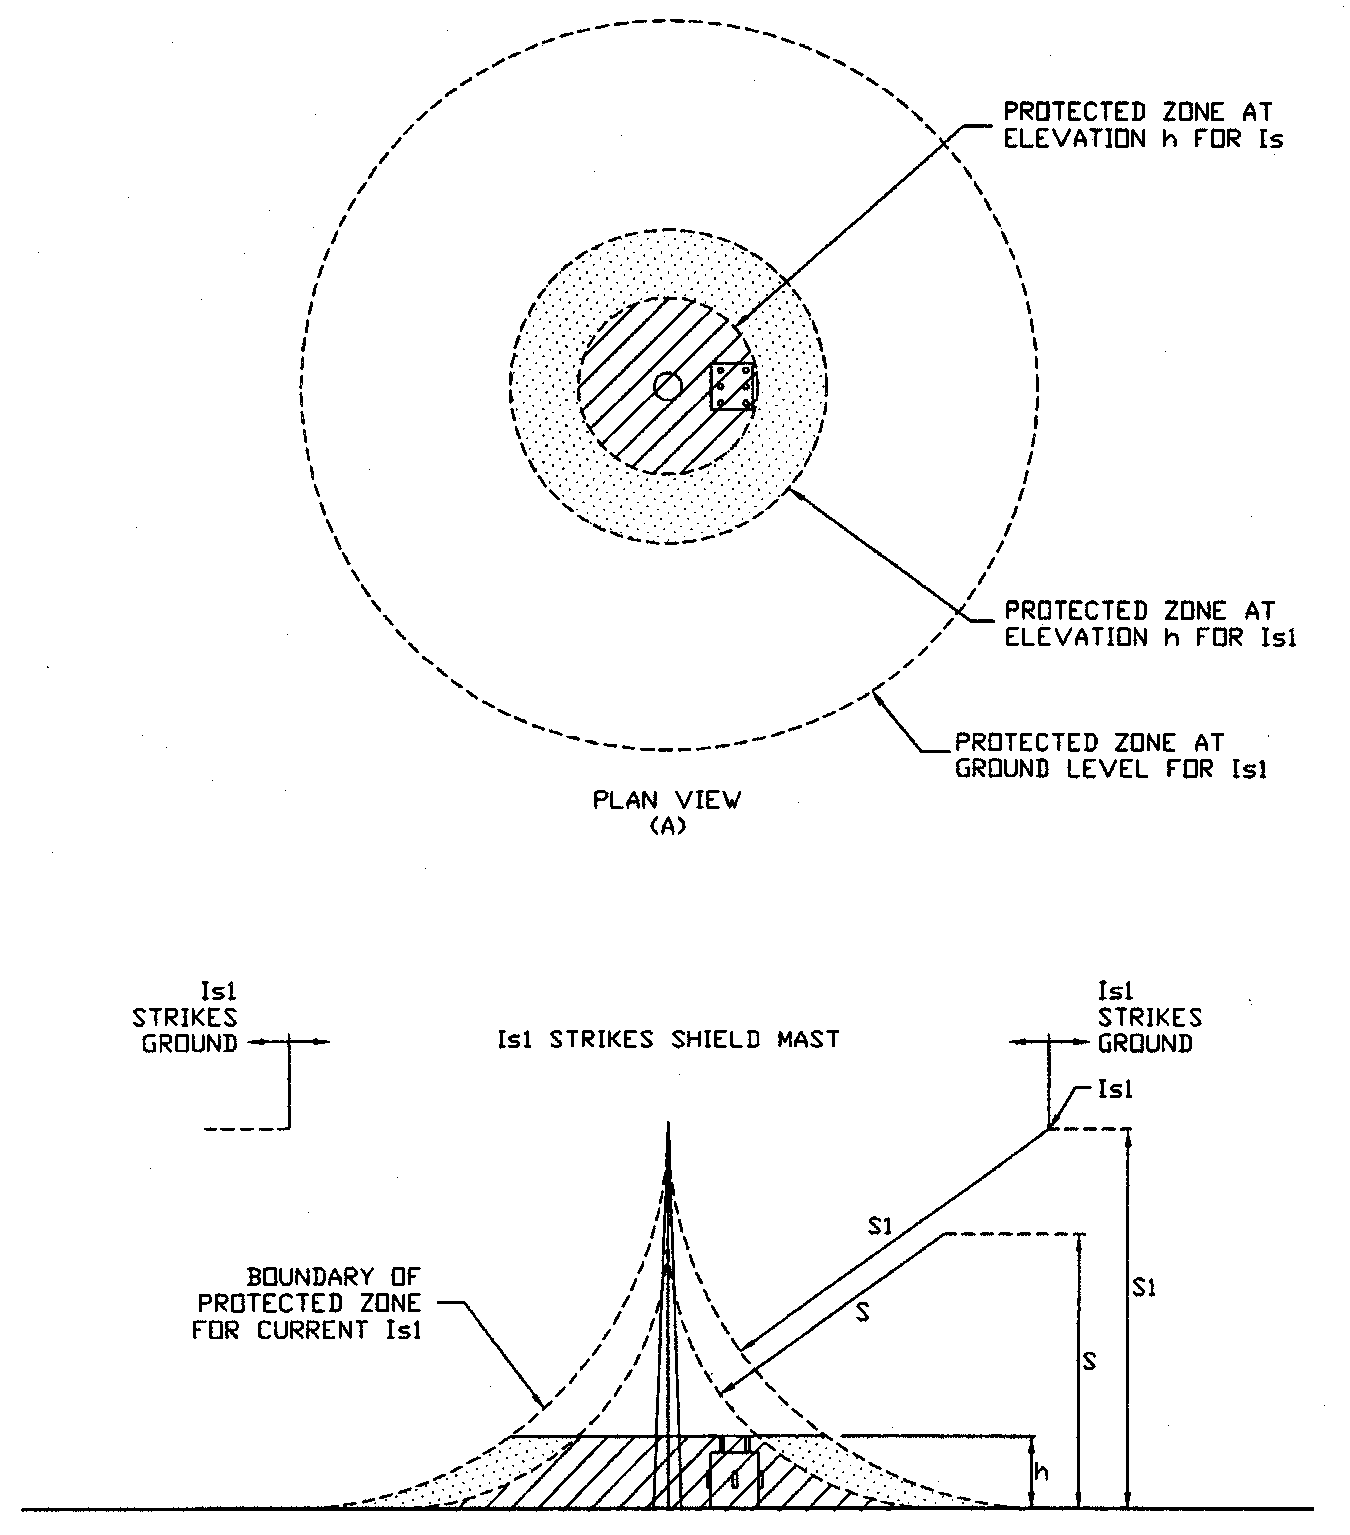

Stepped leaders that result in stroke current Is1 and that descend outside of the point where the arc is tangent to the ground will strike the ground. 

Stepped leaders that result in stroke current Is1 and that descend inside the point where the arc is tangent to the ground will strike the shield mast, provided all other objects are within the S1  protected zone.

Again, the protective zone can be visualized as the surface of a sphere touching the mast. In this case, the sphere has a radius S1.

### Protection against stroke currents less than $I_s$

It has been shown that a shielding system that provides protection at the stroke current level Is provides even better protection for larger stroke currents. 

The remaining scenario to examine is the protection afforded when stroke currents are less than Is.

Consider a stroke current Iso with magnitude less than Is. The striking distance, determined from Eq 5-1, is So. 

The geometrical model for this condition is shown in Þgure 5-6. Arcs of protection for stroke current Iso and Is are both shown. 

The Figure shows that the zone of protection provided by the mast for stroke current Iso is less than the zone of protection provided by the mast for stroke current Is. 

It is noted that a portion of the equipment protrudes above the dashed arc or zone of protection for stroke current Iso. Stepped leaders that result in stroke current Iso and that descend outside of the point where the arc is tangent to the ground will strike the ground. 

However, some stepped leaders that result in stroke current Iso and that descend inside the point where the arc is tangent to the ground could strike the equipment. This is best shown by observing the plan view of protective zones shown in Þgure 5-6. 

Stepped leaders for stroke current Iso that descend inside the inner protective zone will strike the mast and protect equipment that is h in height. 

Stepped leaders for stroke current Iso that descend in the shaded unprotected zone will strike equipment of height h in the area. If, however, the value of Is was selected based on the withstand insulation level of equipment used in the substation, stroke current Iso should cause no damage to equipment.

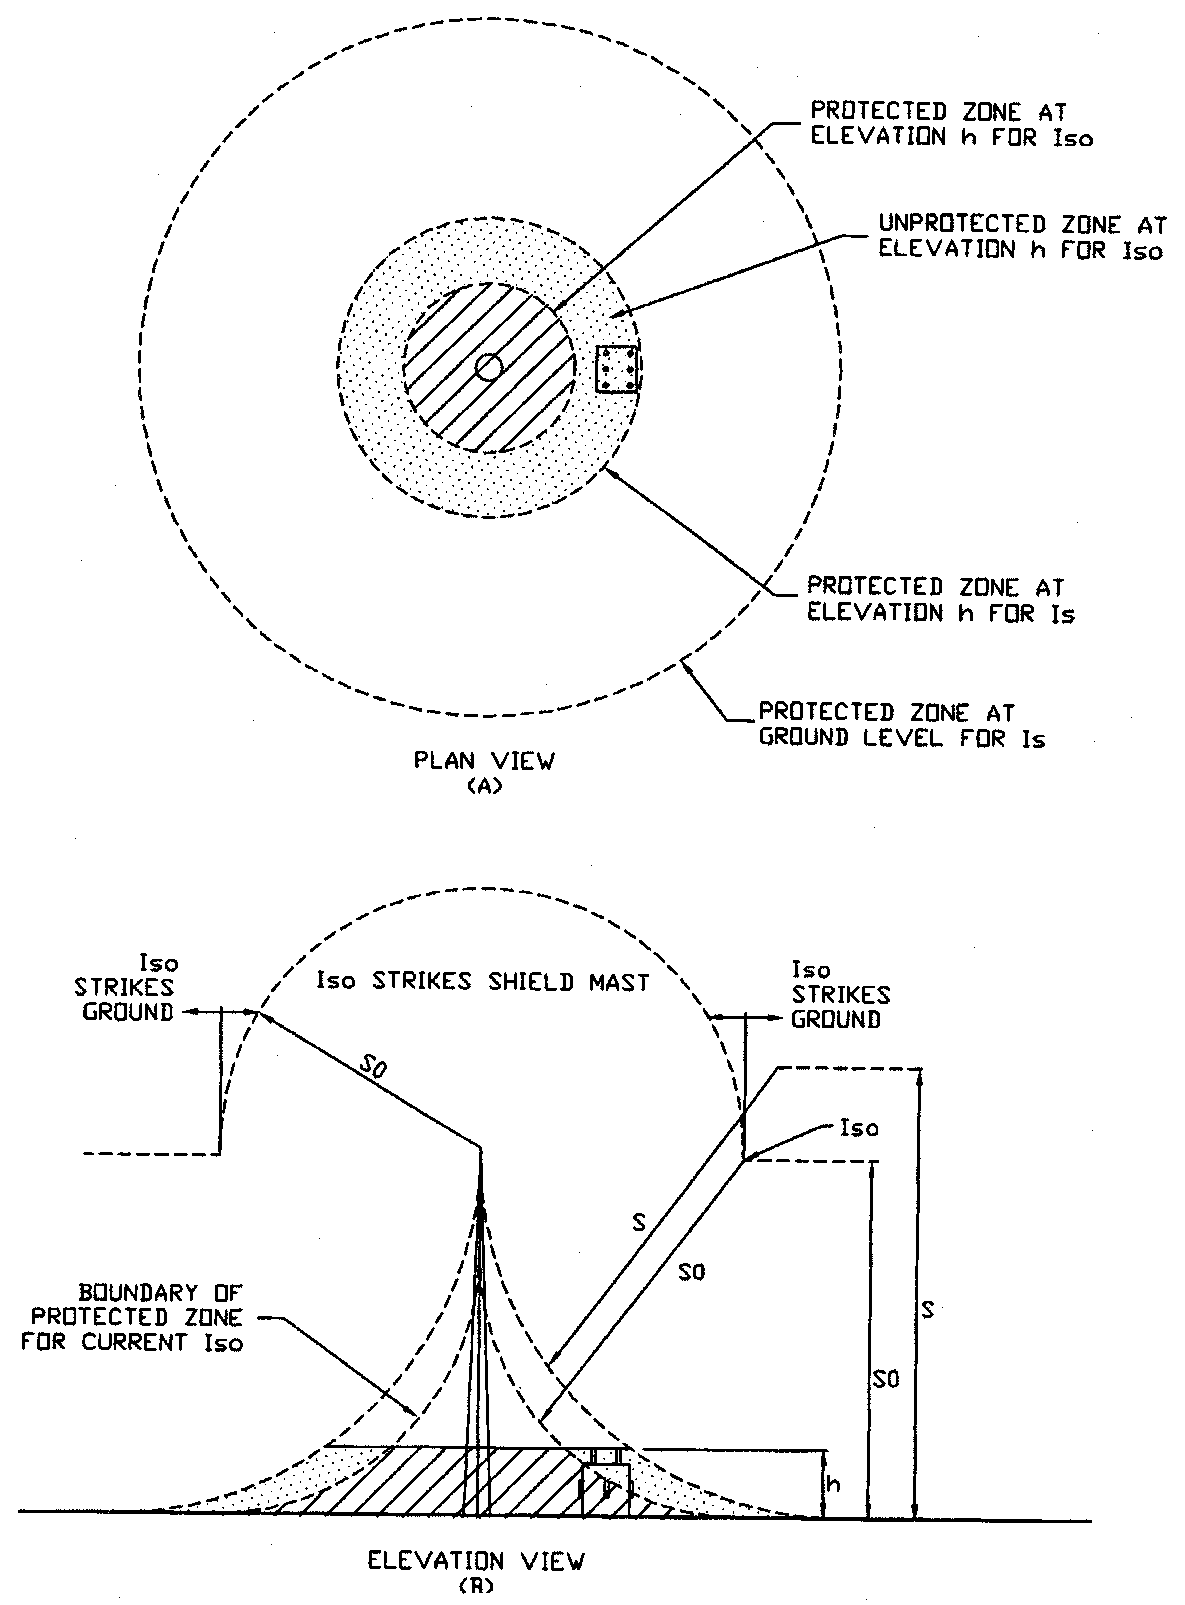